# Notebook 5 — LIDC-IDRI: Malignancy Labels and Features
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## Why a second dataset?
LNDb gives us ~765 nodules with malignancy ratings (Notebook 1) — few for 1136 features, and only
18 nodules rated 5. **LIDC-IDRI** is the largest public collection of CT nodules rated for malignancy:
up to four American radiologists rated every nodule ≥ 3 mm on the same 1–5 scale (LNDb's annotation
protocol was adapted from LIDC's). Can it help?

```
LNDb (Portugal)   CT + malignancy ratings ──┐
                                            ├──► malignancy model ──► LNDb test → predictions.csv   (Notebook 6)
LIDC-IDRI (USA)   CT + malignancy ratings ──┘    (LIDC as extra training data)
```

> **Project history.** Before we found the malignancy ratings in LNDb v4 (Notebook 1), LIDC-IDRI was
> our *only* source of malignancy labels: our early competition submissions came from a model trained
> on LIDC alone. Notebook 6 measures how well that worked on LNDb, now that we can.

For this to work, a nodule must be **described in exactly the same way in both datasets**: same
3D crop, same automatic segmentation, same 1136 features. This notebook prepares LIDC-IDRI:

| Section | Question |
|---|---|
| 2 | Which LIDC scans did we download, and why those? |
| 3 | What does the malignancy rating look like? |
| 4 | How much do radiologists agree on malignancy? (the bar for the model) |
| 5 | What drives a malignancy rating? (size, texture) |
| 6 | Extract the same 1136 features as for LNDb |
| 7 | Does our segmentation work on LIDC too? |
| 8 | How different are the two datasets? (domain shift) |

**Inputs:** `LIDC-IDRI/` (downloaded with `download_lidc.py`), the LIDC annotations shipped with
the `pylidc` library, `outputs/features_train.csv` (Notebook 2, for the comparison)
**Outputs:** `outputs/lidc_nodules.csv`, `outputs/features_lidc.csv`

> ⏱️ Run time: ~5 min for the annotations + ~30–60 min for the features the first time (cached per
> scan afterwards, like Notebook 2).

---

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.impute import SimpleImputer

import lndb_utils as U
import lidc_data as L
from lndb_selection import image_type, readable

plt.rcParams.update(U.PLOT_STYLE)

N_JOBS = -1          # CPU cores for the feature extraction (-1 = all)
MALIGNANCY_COLORS = ['#1a9850', '#91cf60', '#fee08b', '#fc8d59', '#d73027']   # 1 → 5, green → red
DATASET_COLORS = {'LIDC-IDRI': U.COLOR_NEUTRAL, 'LNDb': U.COLOR_ACCENT}
print('Setup complete.')

Setup complete.


## 2. Which scans, and why those?
The full LIDC-IDRI collection is ~130 GB. Because its annotations ship with `pylidc` (no images
needed), we chose the scans **before** downloading: `download_lidc.py` ranks the CT series by the
number of annotated nodules per GB, counting malignant ratings (4–5, the rarest) double, and
downloads the top ~30 GB.

**Consequence to keep in mind:** this selection is *not* a random sample of LIDC — it favours scans
with many nodules and with malignant ones. Section 3 compares it with the whole collection.

In [2]:
selection = pd.read_csv(U.ROOT / 'lidc_selection.csv')
nodules = L.nodule_table(only_downloaded=True)

downloaded = nodules.series_uid.nunique()
print(f'Series in the download list : {len(selection)}  ({selection.patient_id.nunique()} patients)')
print(f'Series found on disk        : {downloaded}  ({nodules.patient_id.nunique()} patients)')
print(f'Nodules (≥ 3 mm) annotated  : {len(nodules)}')
if downloaded < len(selection):
    print(f'⚠️  {len(selection) - downloaded} series not downloaded yet — re-run download_lidc.py to complete them.')

Series in the download list : 357  (350 patients)
Series found on disk        : 357  (350 patients)
Nodules (≥ 3 mm) annotated  : 1635


For comparison we also build the same table for **every** LIDC scan (annotations only — this
needs no images). It takes a few minutes the first time and is cached.

In [3]:
all_path = U.OUTPUT_DIR / 'lidc_nodules_all_scans.csv'
if all_path.exists():
    all_nodules = pd.read_csv(all_path)
else:
    all_nodules = L.nodule_table(only_downloaded=False)
    all_nodules.to_csv(all_path, index=False)
print(f'Whole LIDC-IDRI: {len(all_nodules)} nodules ≥ 3 mm in {all_nodules.patient_id.nunique()} patients')

Whole LIDC-IDRI: 2651 nodules ≥ 3 mm in 875 patients


## 3. The target: malignancy
Each radiologist rated the **likelihood of malignancy** from 1 (highly unlikely) to 5 (highly
suspicious). As in LNDb, a nodule's label is the **average of its readers' ratings**,
rounded to the nearest integer (an average of exactly x.5 is rounded up). The competition expects
exactly such an integer from 1 to 5.

### 3.1 Distribution — our download vs the whole collection

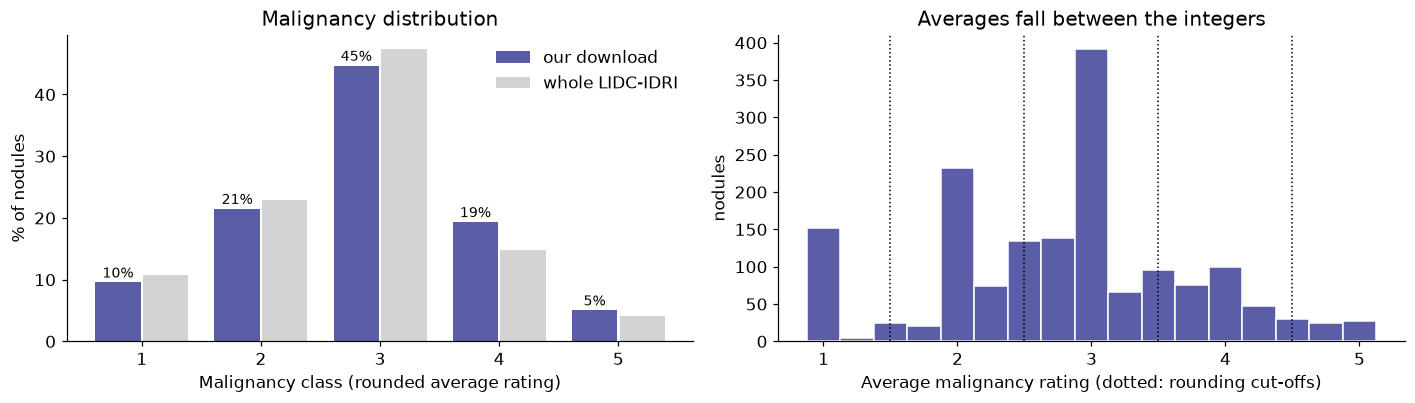

,our download,whole LIDC-IDRI
malignancy_class,,
1,9.5%,10.8%
2,21.5%,22.9%
3,44.6%,47.3%
4,19.3%,14.7%
5,5.0%,4.2%


In [4]:
share = pd.DataFrame({
    'our download': nodules.malignancy_class.value_counts(normalize=True),
    'whole LIDC-IDRI': all_nodules.malignancy_class.value_counts(normalize=True),
}).reindex(range(1, 6)).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(1, 6)
for offset, (name, color) in zip([-0.2, 0.2], [('our download', U.COLOR_NEUTRAL), ('whole LIDC-IDRI', 'lightgray')]):
    axes[0].bar(x + offset, share[name] * 100, width=0.38, color=color, label=name)
for xi, v in zip(x, share['our download']):
    axes[0].text(xi - 0.2, v * 100 + 0.8, f'{v:.0%}', ha='center', fontsize=9)
axes[0].set(xticks=x, xlabel='Malignancy class (rounded average rating)', ylabel='% of nodules',
            title='Malignancy distribution')
axes[0].legend(frameon=False)

axes[1].hist(nodules.malignancy_mean, bins=np.arange(0.875, 5.2, 0.25), color=U.COLOR_NEUTRAL, edgecolor='white')
for t in [1.5, 2.5, 3.5, 4.5]:
    axes[1].axvline(t, color='black', ls=':', lw=1)
axes[1].set(xlabel='Average malignancy rating (dotted: rounding cut-offs)', ylabel='nodules',
            title='Averages fall between the integers')
plt.tight_layout(); plt.show()
share.style.format('{:.1%}')

**Reading it.** Most nodules are rated 2–3 (indeterminate); 5 ("highly suspicious") is rare.
Our download over-represents malignant ratings a little — by design — so in Notebook 6 the model is
evaluated with metrics that do not reward the majority class (balanced accuracy, macro F1, QWK),
exactly the metrics of the competition.

### 3.2 How many radiologists rated each nodule?

In [5]:
counts = nodules.n_readers.clip(upper=4).value_counts().sort_index()
counts.index = [f'{k} reader' + ('s' if k > 1 else '') for k in counts.index]
counts.rename('nodules').to_frame().T

,1 reader,2 readers,3 readers,4 readers
nodules,477,299,298,561


Nodules seen by a single radiologist carry a noisier label (one opinion instead of an
average). We keep them — they are a large share of the data — and Notebook 6 checks whether the model
is less accurate on them.

## 4. How much do radiologists agree on malignancy?
As for LNDb in Notebook 1, the agreement between two radiologists is the realistic bar: we
compare every pair of readers who rated the same nodule.

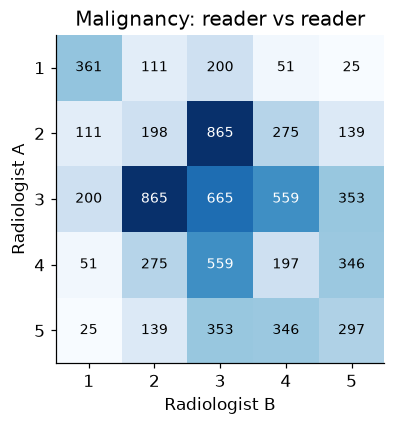

,QWK,exact agreement,within ±1,mean absolute difference
radiologist vs radiologist (4642 pairs),0.466,0.37,0.775,0.906


In [6]:
pairs = L.reader_pairs(nodules)
human = pd.DataFrame({
    'QWK': [cohen_kappa_score(pairs[:, 0], pairs[:, 1], weights='quadratic')],
    'exact agreement': [(pairs[:, 0] == pairs[:, 1]).mean()],
    'within ±1': [(np.abs(pairs[:, 0] - pairs[:, 1]) <= 1).mean()],
    'mean absolute difference': [np.abs(pairs[:, 0] - pairs[:, 1]).mean()],
}, index=[f'radiologist vs radiologist ({len(pairs)} pairs)']).round(3)

conf = pd.crosstab(pairs[:, 0], pairs[:, 1]).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
conf = conf + conf.T - np.diag(np.diag(conf))           # unordered pairs → symmetric
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(conf.values, cmap='Blues')
for i in range(5):
    for j in range(5):
        ax.text(j, i, conf.values[i, j], ha='center', va='center', fontsize=9,
                color='white' if conf.values[i, j] > conf.values.max() / 2 else 'black')
ax.set_xticks(range(5), range(1, 6)); ax.set_yticks(range(5), range(1, 6))
ax.set(xlabel='Radiologist B', ylabel='Radiologist A', title='Malignancy: reader vs reader')
plt.tight_layout(); plt.show()
human

**Reading it.** Radiologists agree *exactly* on a minority of nodules, but almost always
within one point — malignancy is a judgement on a continuous scale, and neighbouring ratings blur
into each other. This is the reference for Notebook 6: a model compared with *one* radiologist
should be judged against this level of agreement. (The competition compares with the *average* of
several radiologists, which is less noisy — so a model can score higher there than one reader vs
another.)

## 5. What drives a malignancy rating?
Two properties are known to drive the radiological suspicion of a nodule: **size** and **texture**.
Neither rating nor diameter is available for the LNDb test nodules — the model must learn them from
the image features — but checking them here tells us what the features need to capture.

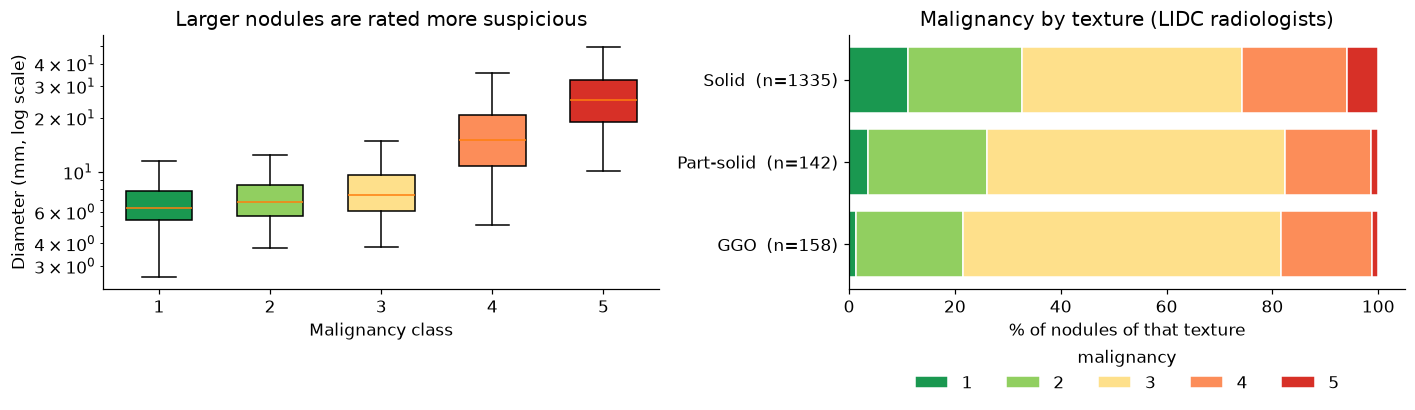

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
groups = [nodules.loc[nodules.malignancy_class == k, 'diameter_mm'] for k in range(1, 6)]
bp = axes[0].boxplot(groups, patch_artist=True, showfliers=False, widths=0.6)
for patch, color in zip(bp['boxes'], MALIGNANCY_COLORS):
    patch.set_facecolor(color)
axes[0].set(xticks=range(1, 6), xticklabels=range(1, 6), yscale='log', xlabel='Malignancy class',
            ylabel='Diameter (mm, log scale)', title='Larger nodules are rated more suspicious')

tex = pd.crosstab(nodules.texture_class.map(dict(enumerate(U.CLASS_NAMES))), nodules.malignancy_class,
                  normalize='index').reindex(U.CLASS_NAMES)
left = np.zeros(len(tex))
for k, color in zip(range(1, 6), MALIGNANCY_COLORS):
    vals = tex.get(k, pd.Series(0, index=tex.index)).values
    axes[1].barh(tex.index, vals * 100, left=left, color=color, edgecolor='white', label=str(k))
    left += vals * 100
counts_tex = nodules.texture_class.map(dict(enumerate(U.CLASS_NAMES))).value_counts()
axes[1].set_yticks(range(len(tex)), [f'{t}  (n={counts_tex.get(t, 0)})' for t in tex.index])
axes[1].set(xlabel='% of nodules of that texture', title='Malignancy by texture (LIDC radiologists)')
axes[1].legend(title='malignancy', frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.show()

**Reading it.** Size is the strongest visible driver: malignancy rises steadily with diameter.
Texture matters too — the share of high ratings differs by texture class. The same two drivers
appear in LNDb (Notebook 1), so the two datasets' radiologists use the scale on similar grounds.

## 6. Feature extraction — exactly as for LNDb
For each nodule, `lidc_data.extract_features` runs the **same functions** as Notebook 2:
crop a 48 mm cube around the centre → automatic segmentation → pyradiomics (1130 features) +
composition (6 features). The centre is the average of the readers' outline centroids — the same
kind of information the LNDb test set provides (a position, nothing else).

Scans are processed in parallel and **cached one by one** (`outputs/cache/lidc_full/`): an
interrupted run resumes where it stopped.

In [8]:
features_lidc = L.extract_features(nodules, n_jobs=N_JOBS)

feature_cols = [c for c in features_lidc.columns if c.startswith(('rad_', 'comp_'))]
keys = ['patient_id', 'scan_id', 'nodule_id']
lidc = nodules.merge(features_lidc, on=keys, how='inner', validate='one_to_one').copy()
failed = (lidc.seg_status == 'error').sum()
print(f'Nodules with features : {len(lidc)} of {len(nodules)}')
print(f'Extraction errors     : {failed}')
print(f'Features              : {len(feature_cols)}')
print('Segmentation outcome  :', lidc.seg_status.value_counts().to_dict())

Nodules with features : 1635 of 1635
Extraction errors     : 2
Features              : 1136
Segmentation outcome  : {'open0': 530, 'open1.5': 448, 'open0.75': 248, 'open2.25': 195, 'clipped': 127, 'open3.0': 63, 'fallback': 22, 'error': 2}


**Feature quality** — the same checks as Notebook 2: missing values and constant features.

In [9]:
lndb = pd.read_csv(U.OUTPUT_DIR / 'features_train.csv')
lndb_features = [c for c in lndb.columns if c.startswith(('rad_', 'comp_'))]
assert feature_cols == lndb_features, 'LIDC and LNDb must have exactly the same features, in the same order'

ok = lidc.seg_status != 'error'
nan_share = lidc.loc[ok, feature_cols].isna().mean()
constant = lidc.loc[ok, feature_cols].nunique() <= 1
print(f'Features with missing values: {(nan_share > 0).sum()}  |  constant features: {constant.sum()}')
print('Same 1136 features, same order as LNDb ✔')

Features with missing values: 0  |  constant features: 0
Same 1136 features, same order as LNDb ✔


## 7. Does our segmentation work on LIDC too?
LIDC provides each radiologist's outline, so we can measure our automatic segmentation again — Dice
against the **consensus** (voxels outlined by at least half of the readers) — and compare with the
LNDb result of Notebook 2. A similar Dice means the segmentation, tuned on LNDb, transfers.

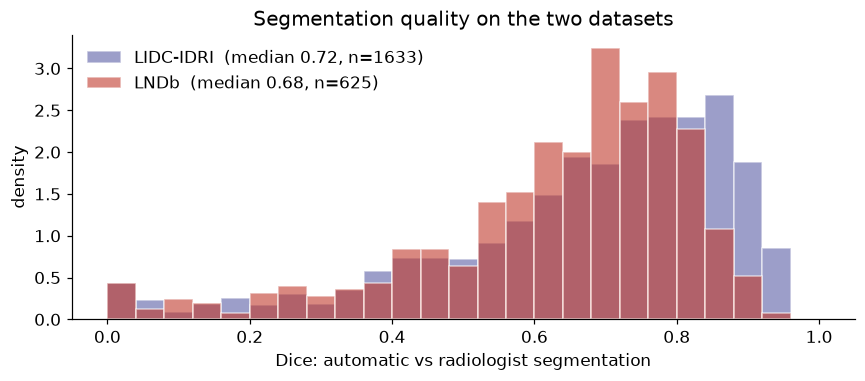

In [10]:
dice = pd.DataFrame({'Dice': pd.concat([lidc.dice_vs_radiologist, lndb.dice_vs_radiologist]),
                     'dataset': ['LIDC-IDRI'] * len(lidc) + ['LNDb'] * len(lndb)}).dropna()

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0, 1, 26)
for name, color in DATASET_COLORS.items():
    d = dice.loc[dice.dataset == name, 'Dice']
    ax.hist(d, bins=bins, alpha=0.6, color=color, edgecolor='white',
            label=f'{name}  (median {d.median():.2f}, n={len(d)})', density=True)
ax.set(xlabel='Dice: automatic vs radiologist segmentation', ylabel='density',
       title='Segmentation quality on the two datasets')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

## 8. How different are the two datasets?
A model trained on LIDC (American hospitals, scanners from the 2000s) will be applied to LNDb
(Portuguese hospital, 2016–2018). If the features of the two datasets differ systematically — for
reasons that have nothing to do with the nodules (scanner, reconstruction, slice thickness) — the
model may be thrown off. This is called **domain shift**.

### 8.1 Can a model tell which dataset a nodule comes from?
A direct test: train a simple classifier to predict *"LIDC or LNDb?"* from the features, with
grouped cross-validation. An AUC near 0.5 means the datasets are indistinguishable; near 1.0 means
every nodule carries a "fingerprint" of its dataset.

In [11]:
both = pd.concat([lidc.loc[ok, feature_cols].copy().assign(dataset=1, group='L' + lidc.loc[ok, 'patient_id']),
                  lndb[feature_cols].copy().assign(dataset=0, group='N' + lndb.LNDbID.astype(str))],
                 ignore_index=True)
domain_model = make_pipeline(SimpleImputer(strategy='median'),
                             QuantileTransformer(n_quantiles=200, output_distribution='normal'),
                             StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
cv = StratifiedGroupKFold(5, shuffle=True, random_state=U.RANDOM_STATE)
p_lidc = cross_val_predict(domain_model, both[feature_cols].values, both.dataset.values,
                           groups=both.group.values, cv=cv, method='predict_proba')[:, 1]
domain_auc = roc_auc_score(both.dataset, p_lidc)
print(f'"LIDC or LNDb?" classifier — AUC = {domain_auc:.3f}')

# Which kinds of features carry the fingerprint? Per-feature AUC, grouped by image version.
from sklearn.metrics import roc_auc_score as auc
single = pd.Series({f: max(auc(both.dataset, both[f].fillna(both[f].median())),
                           1 - auc(both.dataset, both[f].fillna(both[f].median()))) for f in feature_cols})
by_source = single.groupby([image_type(f) for f in single.index]).median().reindex(
    ['original', 'wavelet', 'LoG', 'composition'])
by_source.rename('median single-feature AUC').round(3).to_frame()

"LIDC or LNDb?" classifier — AUC = 0.983


,median single-feature AUC
original,0.687
wavelet,0.834
LoG,0.636
composition,0.602


**Reading it.** The answer is clear: **AUC ≈ 0.98** — almost every nodule carries a
"fingerprint" of its dataset. The fingerprint is strongest in the **wavelet** features (fine,
filtered textures that depend on the scanner's noise and reconstruction), weakest in the
**composition** features, which are defined in physical units (HU thresholds, mm³).

### 8.2 Do the key features look alike?
Three features that mean the same thing on any scanner — how solid, how ground-glass and how big the
nodule is — shown for both datasets:

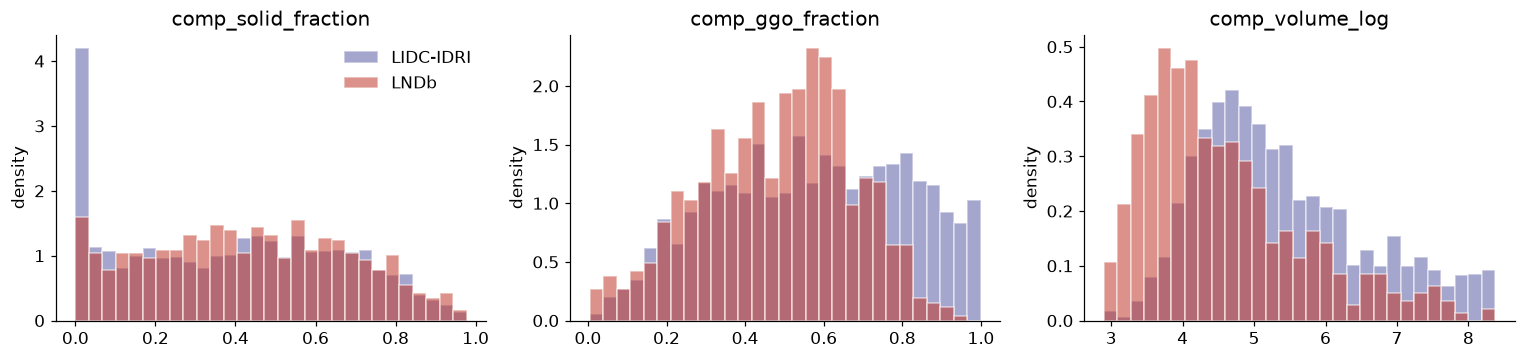

In [12]:
show = ['comp_solid_fraction', 'comp_ggo_fraction', 'comp_volume_log']
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, f in zip(axes, show):
    lo, hi = np.nanpercentile(both[f], [1, 99])
    bins = np.linspace(lo, hi, 30)
    for name, value in [('LIDC-IDRI', 1), ('LNDb', 0)]:
        ax.hist(both.loc[both.dataset == value, f], bins=bins, density=True, alpha=0.55,
                color=DATASET_COLORS[name], edgecolor='white', label=name)
    ax.set(title=readable(f), ylabel='density')
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

Part of the difference is **real population difference**, not scanner: LIDC nodules are larger
(LIDC only annotates nodules ≥ 3 mm, and our download favours nodules rated malignant, which are
larger), while LNDb also includes the smallest ones. LIDC nodules also show more ground-glass-range
voxels, consistent with thicker slices and older scanners (more partial-volume blur at the edges).

**What this means for Notebook 6.** A model trained on LIDC could learn things that only hold on
LIDC's scanners and population. We do not assume the transfer works: Notebook 6 **measures it on the
LNDb nodules**, comparing a model trained on LIDC alone, on LNDb alone, and on both. Every feature
also goes through a quantile transform fitted on the training data, which removes differences in
scale and skew.

## 9. Save

In [13]:
label_cols = ['patient_id', 'scan_id', 'nodule_id', 'series_uid', 'slice_thickness', 'n_readers',
              'malignancy_ratings', 'malignancy_mean', 'malignancy_sd', 'malignancy_class',
              'texture_ratings', 'texture_mean', 'texture_class', 'diameter_mm', 'seg_status', 'dice_vs_radiologist']
lidc.loc[ok, label_cols + feature_cols].to_csv(U.OUTPUT_DIR / 'features_lidc.csv', index=False)
nodules.to_csv(U.OUTPUT_DIR / 'lidc_nodules.csv', index=False)
print(f'Saved features_lidc.csv: {ok.sum()} nodules × {len(feature_cols)} features')

Saved features_lidc.csv: 1633 nodules × 1136 features


## Summary
| Finding | Consequence for Notebook 6 |
|---|---|
| LIDC-IDRI has ~1630 nodules rated for malignancy on LNDb's 1–5 scale | Candidate extra training data for the LNDb model |
| Our download favours scans with many and malignant nodules | Evaluate with balanced metrics (the competition's) |
| Radiologists agree only moderately on malignancy | Human agreement is the reference; labels are noisy |
| Size and texture drive malignancy ratings, as in LNDb | Readers use the scale on similar grounds |
| Same 1136 features, extracted the same way | One feature space for both datasets |
| The datasets differ (domain shift, a more malignant population) | Measure on LNDb whether LIDC helps; LIDC weighted down, cut-offs from LNDb |

**Next → Notebook 6:** train, validate and interpret the malignancy model, and produce `predictions.csv`.